<a href="https://colab.research.google.com/github/LTeamHackathon/L_Team_Hackaathon_Repository/blob/main/H1N1_Hackathon_DatasetB_yashu.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# H1N1 Vaccine Hackathon – Dataset B
**MSc Data Science | EDA → Pre-processing → Modelling → Cost-based evaluation → Submissions**

**Goal:** predict `h1n1_vaccine` (1 = vaccinated) and minimise a *business cost*, not accuracy/F1.
Costs given: vaccine = **$500**, hospitalisation = **$25,000**.

**Notebook outline**
1. Setup & data loading
2. Exploratory data analysis
3. Pre-processing
4. Evaluation metric (cost-sensitive)
5. Modelling, tuning & cross-validation
6. Ensembles & threshold optimisation
7. Sensitivity to the cost assumption
8. Final ranking & submission files
9. Conclusions

## 1. Setup & data loading
Run the next cell, then **upload** `dataset_B_training.csv` and `dataset_B_testing.csv` (and optionally the example submission) when prompted.

In [3]:
!pip -q install lightgbm
import pandas as pd, numpy as np, warnings, os
import matplotlib.pyplot as plt, seaborn as sns
warnings.filterwarnings('ignore')
sns.set_theme(style='whitegrid')
RANDOM_STATE = 42

try:
    from google.colab import files
    if not os.path.exists('/content/drive/MyDrive/dataset_B_training.csv'):
        files.upload()
    DATA_DIR = ''
except ImportError:
    DATA_DIR = ''   # running locally: put CSVs next to the notebook

train = pd.read_csv(DATA_DIR + '/content/drive/MyDrive/dataset_B_training.csv')
test  = pd.read_csv(DATA_DIR + '/content/drive/MyDrive/dataset_B_testing.csv')
print(train.shape, test.shape)
train.head()

(4756, 31) (4749, 30)


,respondent_id,h1n1_concern,h1n1_knowledge,behavioral_antiviral_meds,behavioral_avoidance,behavioral_face_mask,behavioral_wash_hands,behavioral_large_gatherings,behavioral_outside_home,behavioral_touch_face,...,income_poverty,marital_status,rent_or_own,employment_status,census_msa,household_adults,household_children,employment_sector,number_chronic_med_conditions,h1n1_vaccine
0,1,1.0,2.0,0.0,1.0,0.0,1.0,0.0,0.0,1.0,...,"<= $75,000, Above Poverty",Married,Own,Employed,"MSA, Not Principle City",2.0,1.0,science,0,0
1,2,1.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,Below Poverty,Not Married,Own,Employed,Non-MSA,0.0,3.0,wholesale,0,0
2,3,2.0,1.0,0.0,1.0,0.0,1.0,0.0,0.0,1.0,...,"> $75,000",Not Married,Own,Employed,"MSA, Principle City",0.0,0.0,education,0,1
3,4,0.0,1.0,0.0,1.0,0.0,1.0,0.0,0.0,1.0,...,"<= $75,000, Above Poverty",Not Married,Rent,Not in Labor Force,Non-MSA,0.0,0.0,NaN,0,0
4,5,2.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,NaN,Not Married,NaN,Unemployed,Non-MSA,3.0,0.0,NaN,0,0


## 2. Exploratory Data Analysis

### 2.1 Structure, types and target balance

In [4]:
train.info()
print(train['h1n1_vaccine'].value_counts(normalize=True).round(3))
print('Duplicate IDs:', train.respondent_id.duplicated().sum())
train.describe().T.round(2)

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 4756 entries, 0 to 4755
Data columns (total 31 columns):
 #   Column                         Non-Null Count  Dtype  
---  ------                         --------------  -----  
 0   respondent_id                  4756 non-null   int64  
 1   h1n1_concern                   4741 non-null   float64
 2   h1n1_knowledge                 4734 non-null   float64
 3   behavioral_antiviral_meds      4739 non-null   float64
 4   behavioral_avoidance           4729 non-null   float64
 5   behavioral_face_mask           4752 non-null   float64
 6   behavioral_wash_hands          4748 non-null   float64
 7   behavioral_large_gatherings    4747 non-null   float64
 8   behavioral_outside_home        4741 non-null   float64
 9   behavioral_touch_face          4736 non-null   float64
 10  doctor_recc_h1n1               4437 non-null   float64
 11  child_under_6_months           4622 non-null   float64
 12  health_worker                  4625 non-null   f

,count,mean,std,min,25%,50%,75%,max
respondent_id,4756.0,2378.50,1373.08,1.0,1189.75,2378.5,3567.25,4756.0
h1n1_concern,4741.0,1.66,0.89,0.0,1.00,2.0,2.00,3.0
h1n1_knowledge,4734.0,1.31,0.61,0.0,1.00,1.0,2.00,2.0
behavioral_antiviral_meds,4739.0,0.06,0.23,0.0,0.00,0.0,0.00,1.0
behavioral_avoidance,4729.0,0.74,0.44,0.0,0.00,1.0,1.00,1.0
behavioral_face_mask,4752.0,0.08,0.27,0.0,0.00,0.0,0.00,1.0
behavioral_wash_hands,4748.0,0.84,0.36,0.0,1.00,1.0,1.00,1.0
behavioral_large_gatherings,4747.0,0.36,0.48,0.0,0.00,0.0,1.00,1.0
behavioral_outside_home,4741.0,0.34,0.47,0.0,0.00,0.0,1.00,1.0
behavioral_touch_face,4736.0,0.70,0.46,0.0,0.00,1.0,1.00,1.0


In [2]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


**Observation:** the target is moderately imbalanced (~39% vaccinated). No duplicate IDs. Most columns are binary/ordinal survey answers, the rest are categorical strings.

### 2.2 Missing values

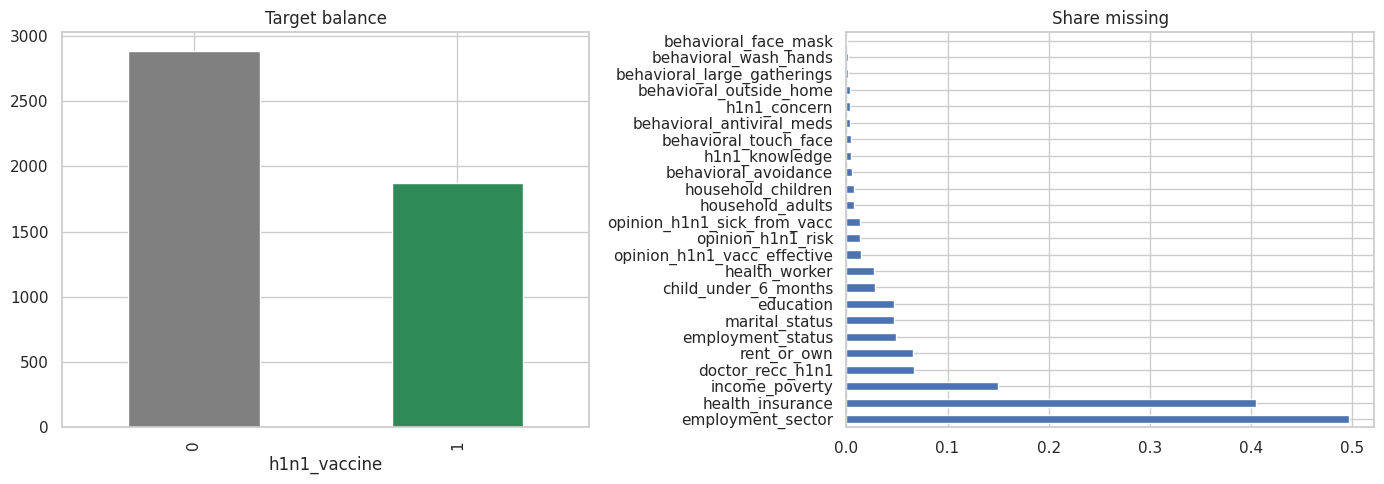

In [5]:
miss = train.isna().mean().sort_values(ascending=False)
miss = miss[miss>0]
fig, ax = plt.subplots(1,2, figsize=(14,5))
train['h1n1_vaccine'].value_counts().plot.bar(ax=ax[0], color=['grey','seagreen']); ax[0].set_title('Target balance')
miss.plot.barh(ax=ax[1]); ax[1].set_title('Share missing'); plt.tight_layout(); plt.show()

**Is missingness informative?** If the vaccination rate differs between missing and non-missing rows, the *fact of being missing* is a signal (MNAR-like) and we should keep an indicator rather than just impute.

In [6]:
rows=[]
for c in ['health_insurance','employment_sector','doctor_recc_h1n1','income_poverty','education','rent_or_own']:
    g = train.groupby(train[c].isna())['h1n1_vaccine'].mean()
    rows.append({'feature':c,'rate_if_present':g.get(False),'rate_if_missing':g.get(True)})
pd.DataFrame(rows).round(3)

,feature,rate_if_present,rate_if_missing
0,health_insurance,0.502,0.236
1,employment_sector,0.403,0.385
2,doctor_recc_h1n1,0.409,0.182
3,income_poverty,0.399,0.365
4,education,0.398,0.321
5,rent_or_own,0.397,0.352


**Finding:** `health_insurance` and `doctor_recc_h1n1` have clearly different vaccination rates when missing → we will add **missing-indicator features**.

### 2.3 Vaccination rate by categorical features

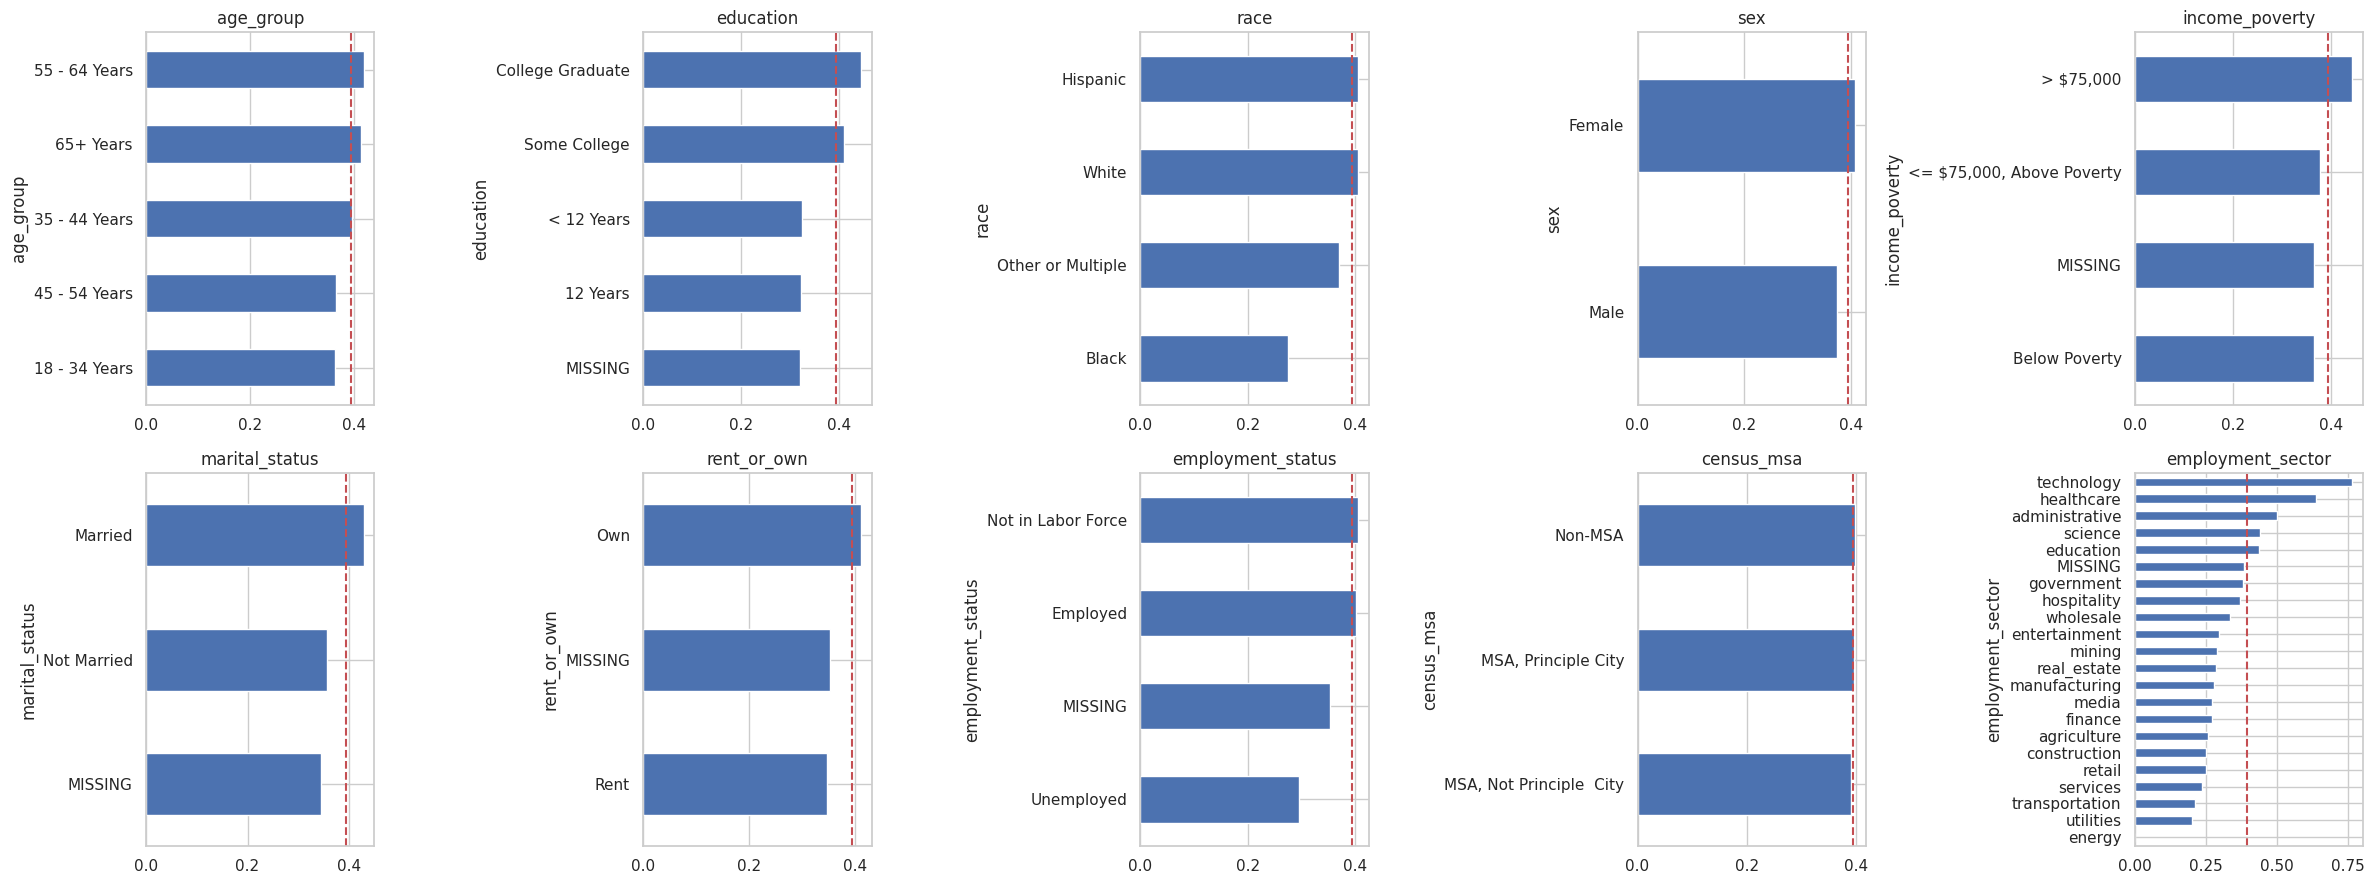

In [7]:
cats = [c for c in train.columns if str(train[c].dtype) in ('str','object')]
fig, axs = plt.subplots(2,5, figsize=(24,9))
for a,c in zip(axs.ravel(), cats):
    train.fillna({c:'MISSING'}).groupby(c)['h1n1_vaccine'].mean().sort_values().plot.barh(ax=a)
    a.axvline(train.h1n1_vaccine.mean(), c='r', ls='--'); a.set_title(c)
plt.tight_layout(); plt.show()

**Observation:** vaccination increases with age, education and income; employment sector and race show moderate differences. Red line = overall rate.

### 2.4 Vaccination rate by numeric / ordinal features

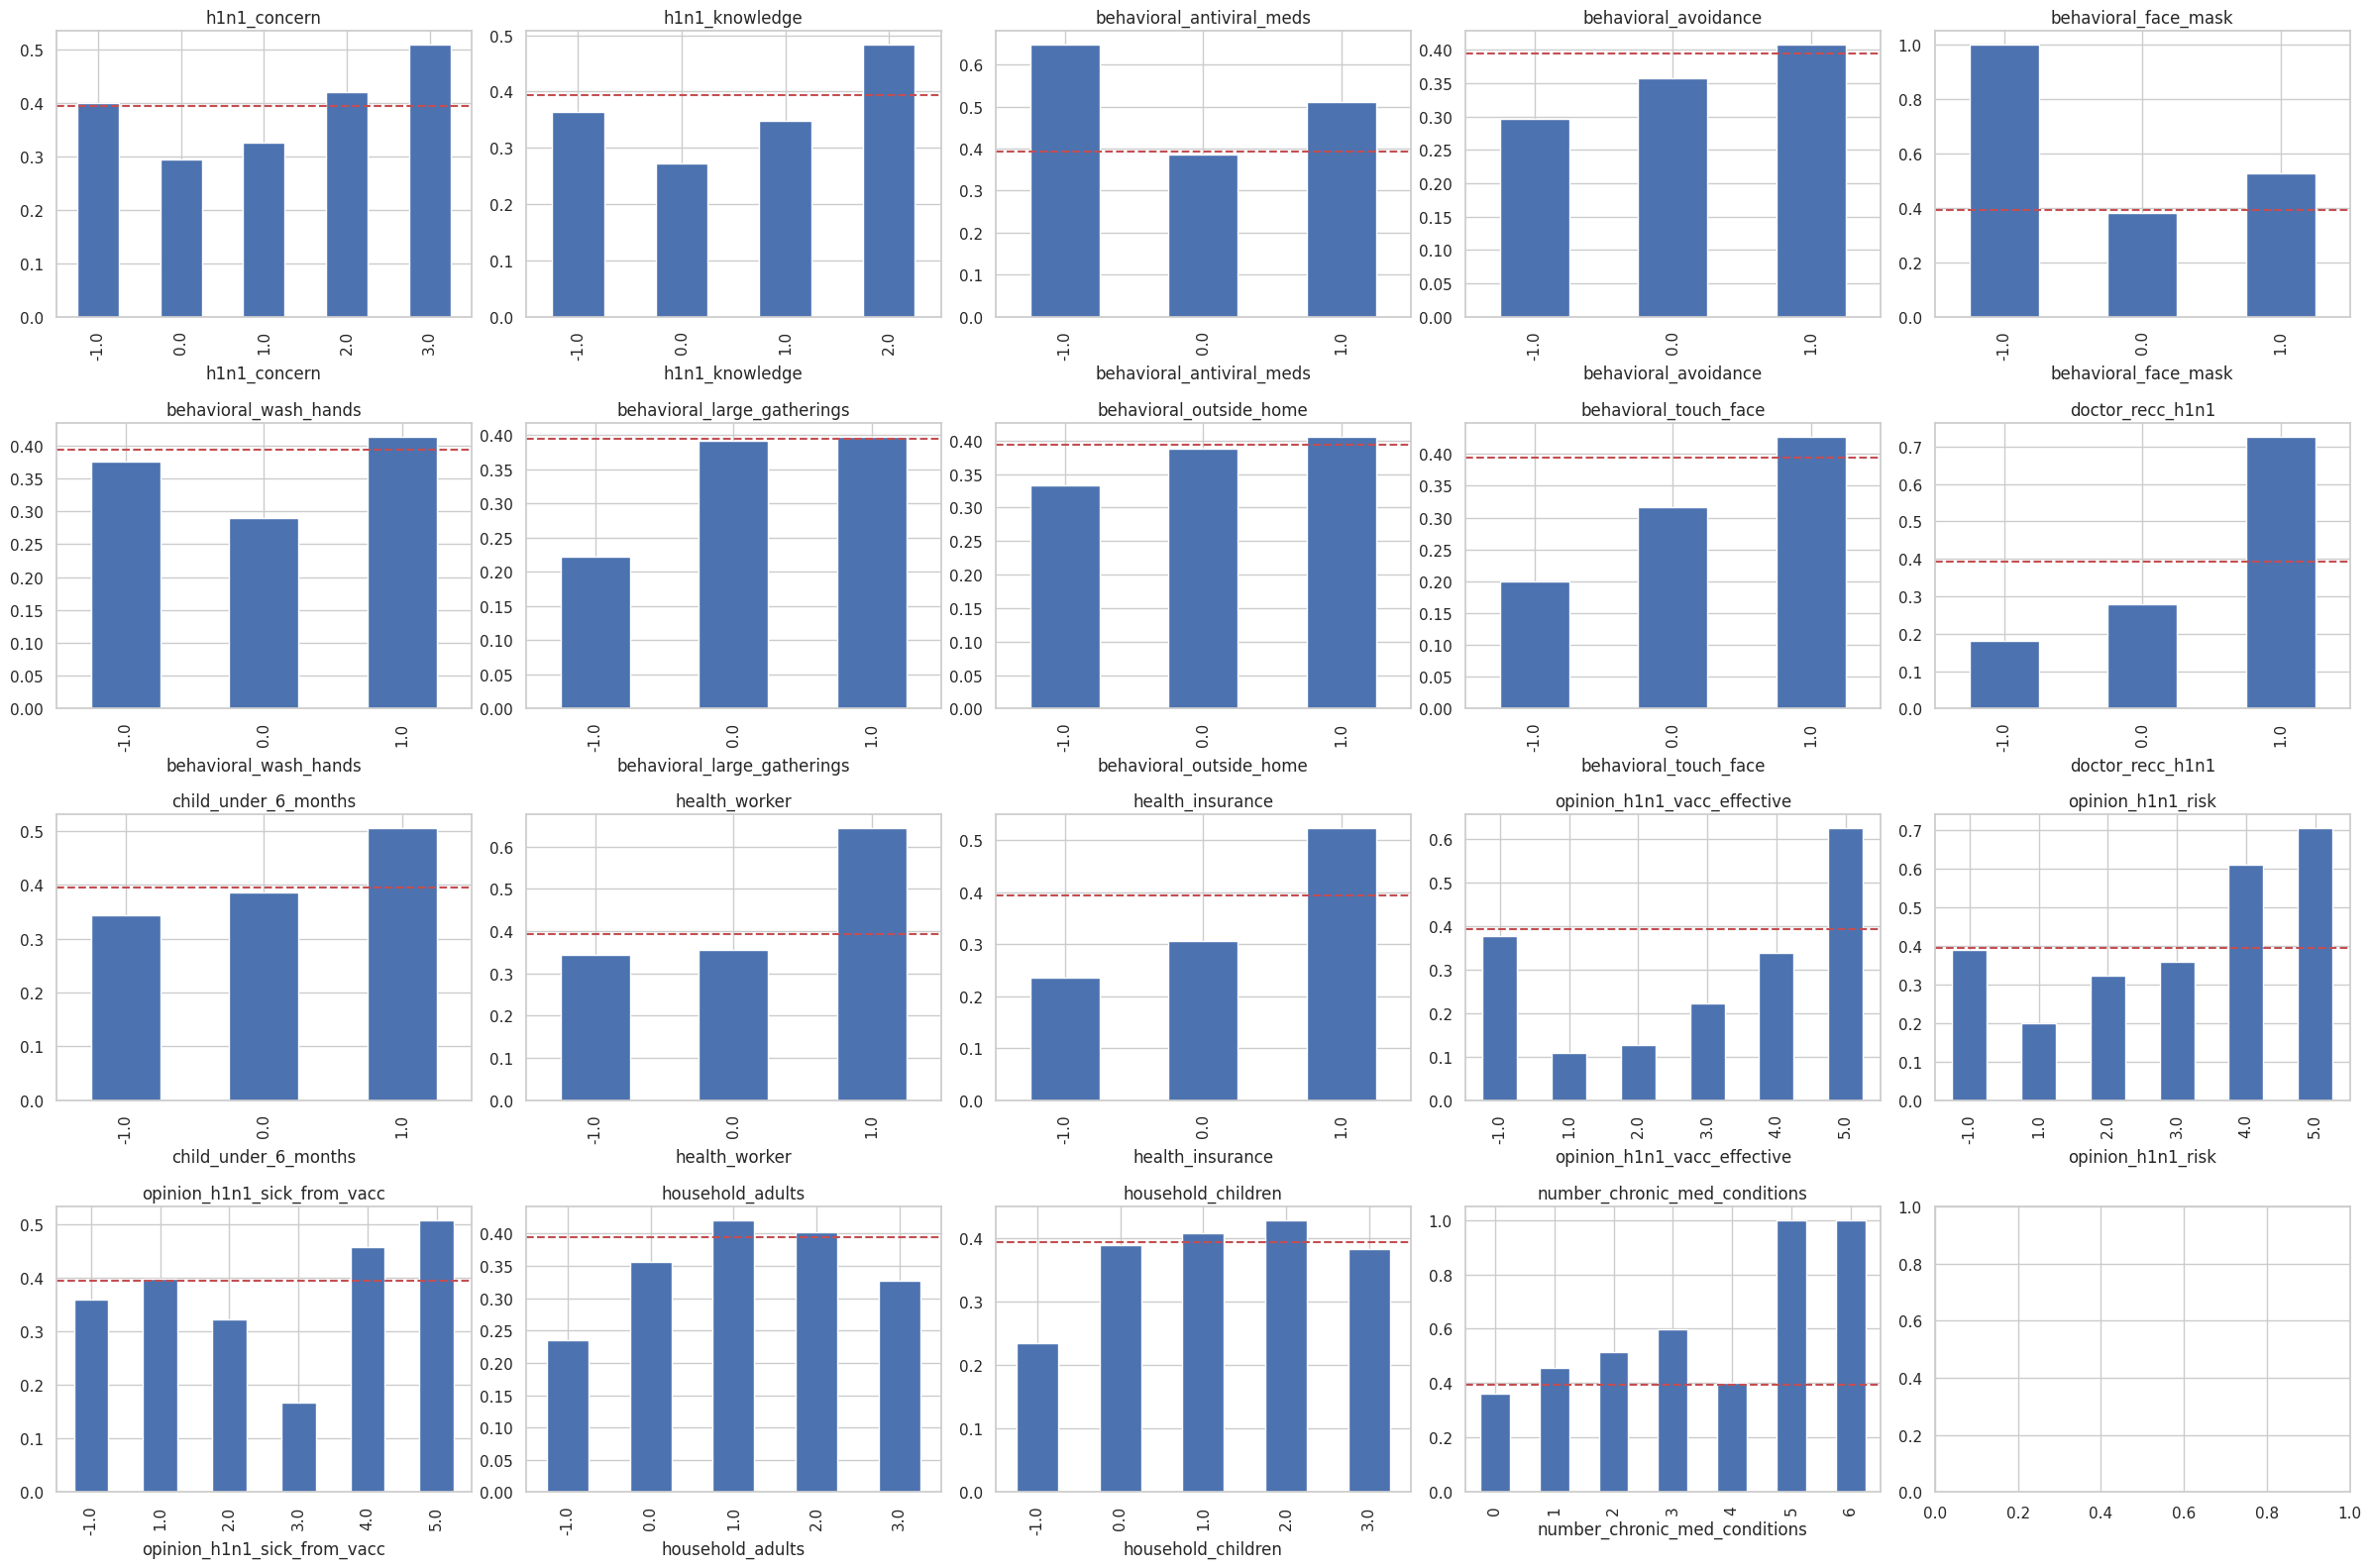

In [8]:
num = [c for c in train.columns if c not in cats+['h1n1_vaccine','respondent_id']]
fig, axs = plt.subplots(4,5, figsize=(24,16))
for a,c in zip(axs.ravel(), num):
    train.fillna({c:-1}).groupby(c)['h1n1_vaccine'].mean().plot.bar(ax=a); a.axhline(train.h1n1_vaccine.mean(), c='r', ls='--'); a.set_title(c)
plt.tight_layout(); plt.show()

**Observation:** a doctor's recommendation, perceived risk and perceived vaccine effectiveness are the strongest drivers; most `behavioral_*` variables are weak.

### 2.5 Correlation with the target

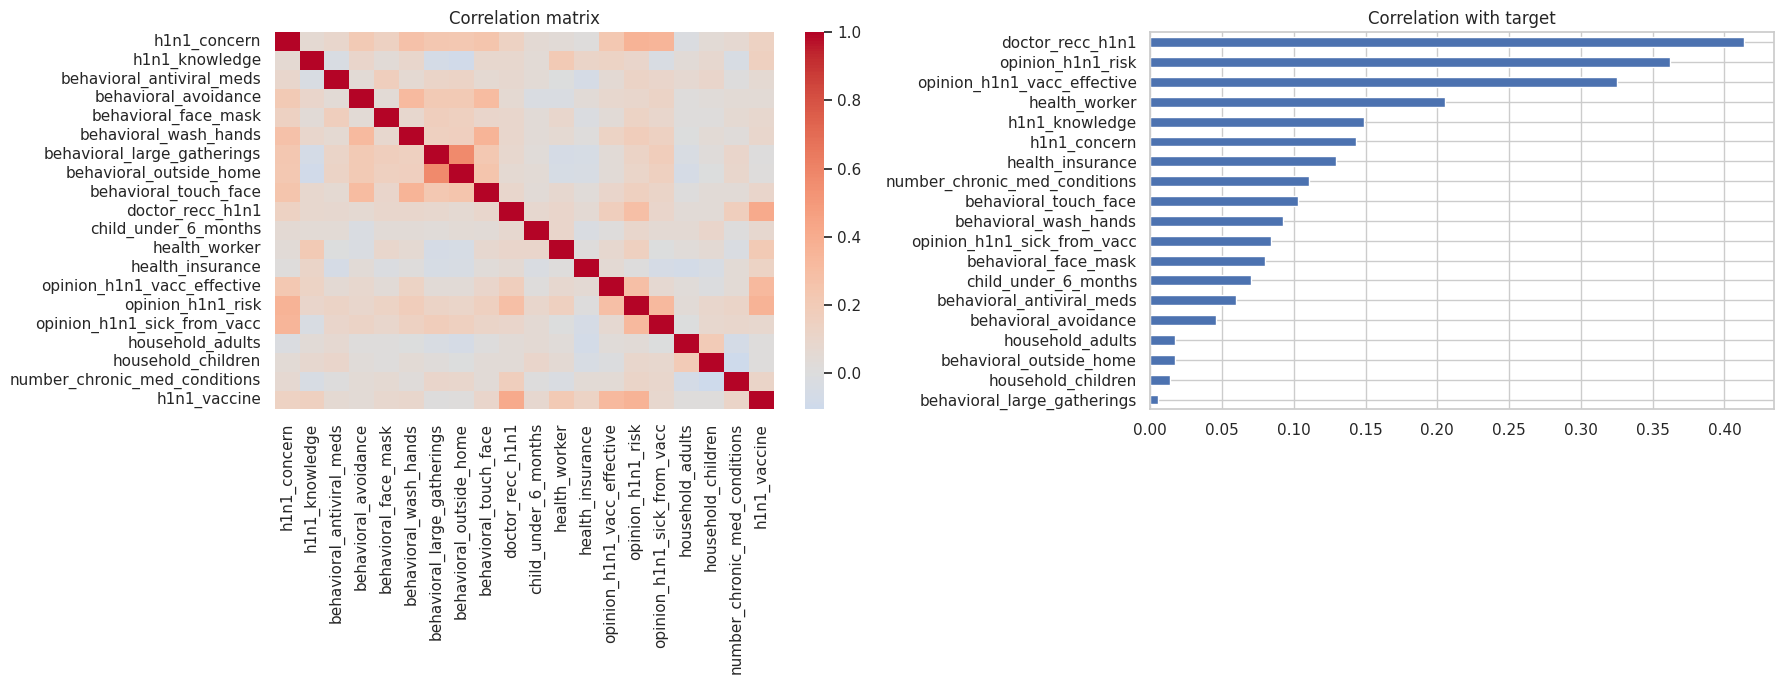

In [9]:
corr = train[num+['h1n1_vaccine']].corr()
fig, ax = plt.subplots(1,2, figsize=(18,7))
sns.heatmap(corr, cmap='coolwarm', center=0, ax=ax[0]); ax[0].set_title('Correlation matrix')
corr['h1n1_vaccine'].drop('h1n1_vaccine').sort_values().plot.barh(ax=ax[1]); ax[1].set_title('Correlation with target')
plt.tight_layout(); plt.show()

**Takeaway:** no severe multicollinearity (no pair beyond ~0.6), so linear models are safe; signal is concentrated in ~6 features.

## 3. Pre-processing
Two feature sets are built so each model family gets what it needs:

| Set | Used by | Treatment |
|---|---|---|
| `ohe` | Logistic regression, Random forest, HistGB | one-hot for nominal, ordinal maps for age/education, median impute, scaling (LogReg) |
| `tree` | LightGBM | category dtype + native NaN handling |

**Engineered features:** missing indicators, `n_precautions` (sum of behavioural actions), `opinion_gap` (effectiveness − fear of side-effects).

In [10]:
ids = test['respondent_id'].copy()
y = train.pop('h1n1_vaccine').values
train = train.drop(columns='respondent_id'); test = test.drop(columns='respondent_id')
CAT = [c for c in train.columns if str(train[c].dtype) in ('str','object')]
ORD = {'age_group':['18 - 34 Years','35 - 44 Years','45 - 54 Years','55 - 64 Years','65+ Years'],
       'education':['< 12 Years','12 Years','Some College','College Graduate']}

def prep(df, kind):
    d = df.copy()
    for c in ['health_insurance','doctor_recc_h1n1','employment_sector','income_poverty','education']:
        d[c+'_miss'] = d[c].isna().astype(int)
    for c,o in ORD.items():
        d[c+'_ord'] = d[c].map({v:i for i,v in enumerate(o)})
    d['n_precautions'] = d[[c for c in d if c.startswith('behavioral')]].sum(axis=1)
    d['opinion_gap'] = d['opinion_h1n1_vacc_effective'] - d['opinion_h1n1_sick_from_vacc']
    if kind=='ohe':
        d = pd.get_dummies(d, columns=CAT, dtype=float)
        d = d.fillna(d.median())
    else:
        for c in CAT: d[c] = d[c].fillna('MISSING').astype('category')
    return d

full = pd.concat([train, test]); n = len(train)     # concat so dummy columns align
X_ohe, X_tree = prep(full,'ohe'), prep(full,'tree')
Xo_tr, Xo_te = X_ohe.iloc[:n], X_ohe.iloc[n:]
Xt_tr, Xt_te = X_tree.iloc[:n], X_tree.iloc[n:]
print(Xo_tr.shape, Xt_tr.shape)

(4756, 77) (4756, 38)


## 4. Evaluation metric – derived from the official "Target Metric Information" sheet
**Goal:** minimise the *total money spent by the town* = **vaccine costs + hospitalisation costs**.

**Rules from the sheet**
* Everyone gets infected (100 %), so hospitalisation risk depends only on person-level factors **and vaccination status**.
* Everyone who *wants* a vaccine must get one. If we do **not** supply one, the town **pays them the vaccine cost ($500) instead**.
* Vaccines are posted to homes and **wasted if the person won't use them** → we must predict *who* accepts.
* Hospitalisation costs $25,000 × (expected number hospitalised).

**Cost of each prediction outcome** (prediction = "send vaccine"; actual = person would accept it)

| Outcome | Vaccine cost | Hospitalisation (expected) |
|---|---|---|
| TP – sent, accepted | $500 | $25,000·p_vacc |
| FP – sent, refused (wasted) | $500 | $25,000·p_unvacc |
| FN – not sent, wanted one | $500 (paid instead) | depends on scenario below |
| TN – not sent, didn't want | $0 | $25,000·p_unvacc |

**Ambiguity to flag:** after a *false negative* is the person protected?
* **Scenario 1 (literal):** the cash lets them buy a vaccine → protected (p_vacc). Then FN costs exactly the same as TP, the only controllable mistake is FP (wasted $500), and *predicting nobody* is optimal – the model could not matter.
* **Scenario 2 (default here):** cash is paid but they are **not vaccinated in time** (everyone is infected immediately) → hospitalisation uses p_unvacc.

Under scenario 2, send a vaccine to person *i* only if

$$P_i\,\Delta H_i \;>\; 500\,(1-P_i),\qquad \Delta H_i = 25000\,(p^{unvacc}_i-p^{vacc}_i)$$

i.e. a **person-specific threshold**: high-risk people get a vaccine at much lower acceptance probability than low-risk people. *Ask your instructor which scenario they intend; the code supports both.*

### 4.1 Hospitalisation probability model (parameters from generative-AI research)
$$P(\text{hosp}) = \text{base\_risk}\times \text{age\_mult}\times(1+k\cdot n_{chronic})\times(1-VE\ \text{if vaccinated})$$

| Parameter | Best | Range | Basis |
|---|---|---|---|
| `base_risk` (per **infection**, healthy 35–44, no conditions) | 0.15 % | 0.06–0.4 % | CDC burden estimate (Shrestha 2011): 274,304 hosp / 60.8 M cases = 0.45 % per case; ×0.75 symptomatic fraction → 0.34 % per infection; ÷ ~2.2 average risk multiplier → 0.15 % reference risk |
| `age_mult` 18-34 / 35-44 / 45-54 / 55-64 / 65+ | 0.8 / 1.0 / 1.2 / 1.5 / 1.8 | 65+: 1.2–3.0 | judgement informed by Van Kerkhove 2011, Hancock 2009 (lower attack rate but higher per-infection risk in the old) |
| `chronic_k` | 2.0 | 1.0–4.0 | judgement from CDC (≈80 % of hospitalised adults had an underlying condition) and WHO pooled analysis |
| `vacc_eff` (vs hospitalisation) | 0.60 | 0.40–0.80 | Lansbury 2017 meta-analysis 61 % (14–82); Thompson 2014 50 %; Cheng 2011 49 % |

**Caveats:** age multipliers, `chronic_k` and the symptomatic fraction are judgements, not published values. CDC derived cases from hospitalisations, so its per-case rate is almost constant by age. **Also ask other AIs / people and quote their answers in your report;** replace the values below with your consensus if they differ.

Main sources: Shrestha et al. 2011 *Clin Infect Dis* 52(S1):S75-82; CDC 2009 H1N1 estimates by age group; Reed et al. 2009 *EID*; Van Kerkhove et al. 2011 *PLoS Med* 8(7):e1001053; Hancock et al. 2009 *NEJM*; Lansbury et al. 2017; Thompson et al. 2014 *CID*; Cheng et al. 2011 *Vaccine*.

In [11]:
BASE_RISK  = 0.0015      # per infection, reference person
BASE_RANGE = (0.0006, 0.004)
AGE_MULT   = {'18 - 34 Years':0.8,'35 - 44 Years':1.0,'45 - 54 Years':1.2,'55 - 64 Years':1.5,'65+ Years':1.8}
CHRONIC_K  = 2.0
VAX_EFFECT = 0.60
VAX_RANGE  = (0.40, 0.80)
VACCINE_COST, HOSP_COST = 500, 25000

def hosp_probs(df, base=BASE_RISK, ve=VAX_EFFECT, k=CHRONIC_K):
    """Returns (p_unvaccinated, p_vaccinated) per person."""
    m = df['age_group'].map(AGE_MULT).values * (1 + k*df['number_chronic_med_conditions'].values)
    p_u = np.clip(base*m, 0, 1)
    return p_u, p_u*(1-ve)

p_unv, p_vac = hosp_probs(train)
print('Mean P(hosp | unvaccinated) = %.3f%%   (CDC per-case avg 0.45%%, x0.75 symptomatic = 0.34%% per infection)' % (100*p_unv.mean()))
pd.Series(p_unv).describe().round(4)

Mean P(hosp | unvaccinated) = 0.367%   (CDC per-case avg 0.45%, x0.75 symptomatic = 0.34% per infection)


,0
count,4756.0000
mean,0.0037
std,0.0033
min,0.0012
25%,0.0015
50%,0.0023
75%,0.0054
max,0.0292


### 4.2 Cost function and decision rule

In [12]:
from sklearn.metrics import roc_auc_score, brier_score_loss, log_loss

def total_cost(y_true, pred, Hu, Hv, scenario=2):
    """Total $ spent. Hu/Hv = expected hospitalisation cost if unvaccinated/vaccinated (per person)."""
    y_true, pred = np.asarray(y_true), np.asarray(pred)
    vaccine = VACCINE_COST * ((pred==1) | (y_true==1))                 # sent, or paid instead
    protected = (y_true==1) & ((pred==1) | (scenario==1))              # who ends up vaccinated
    return vaccine.sum() + np.where(protected, Hv, Hu).sum()

def decide(proba, Hu, Hv, scenario=2):
    if scenario==1: return np.zeros(len(proba), int)                    # sending never helps
    dH = Hu - Hv
    return (proba*dH > VACCINE_COST*(1-proba)).astype(int)

Hu, Hv = HOSP_COST*p_unv, HOSP_COST*p_vac
for s in (1,2):
    print(f'--- Scenario {s} ---')
    for nm,pr in {'predict all 0':np.zeros(n,int),'predict all 1':np.ones(n,int),'oracle (perfect)':y}.items():
        print(f'{nm:18s} ${total_cost(y,pr,Hu,Hv,s):>12,.0f}  (${total_cost(y,pr,Hu,Hv,s)/n:,.1f} per person)')

--- Scenario 1 ---
predict all 0      $   1,258,121  ($264.5 per person)
predict all 1      $   2,699,121  ($567.5 per person)
oracle (perfect)   $   1,258,121  ($264.5 per person)
--- Scenario 2 ---
predict all 0      $   1,373,204  ($288.7 per person)
predict all 1      $   2,699,121  ($567.5 per person)
oracle (perfect)   $   1,258,121  ($264.5 per person)


**Observation:** in scenario 1 the oracle and 'predict all 0' tie – confirming the point above. In scenario 2 perfect knowledge of who accepts has real value, and 'send to everyone' is very expensive (wasted vaccines).

## 5. Modelling, tuning & cross-validation
The model's job is now to output a **well-calibrated P(accepts vaccine)** for every person; the decision rule above turns probabilities into actions. So we judge models by cost *and* by log-loss/Brier (calibration).

Protocol: 20 % hold-out → `RandomizedSearchCV` (5-fold, AUC) on the rest → 5-fold OOF predictions on all data → refit on everything for the test set.

In [13]:
from sklearn.model_selection import StratifiedKFold, train_test_split, RandomizedSearchCV
from sklearn.base import clone
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
import lightgbm as lgb

skf = StratifiedKFold(5, shuffle=True, random_state=RANDOM_STATE)
folds = list(skf.split(Xo_tr, y))
idx_fit, idx_ho = train_test_split(np.arange(n), test_size=0.2, stratify=y, random_state=1)

models = {
 'LogReg': (lambda: make_pipeline(StandardScaler(), LogisticRegression(C=0.1, max_iter=2000)), 'ohe',
            {'logisticregression__C':[0.01,0.03,0.1,0.3,1]}),
 'RandomForest': (lambda: RandomForestClassifier(n_estimators=400, min_samples_leaf=5, n_jobs=-1, random_state=0), 'ohe',
            {'min_samples_leaf':[3,5,10,20],'max_features':['sqrt',0.3,0.5],'max_depth':[None,8,12]}),
 'HistGB': (lambda: HistGradientBoostingClassifier(random_state=0), 'ohe',
            {'learning_rate':[0.02,0.05,0.1],'max_leaf_nodes':[4,8,15],'min_samples_leaf':[20,50,100],
             'l2_regularization':[0,1,10],'max_iter':[100,200,300]}),
 'LightGBM': (lambda: lgb.LGBMClassifier(random_state=0, verbose=-1, n_jobs=-1), 'tree',
            {'learning_rate':[0.02,0.05,0.1],'num_leaves':[4,8,15],'n_estimators':[100,200,400],
             'min_child_samples':[20,50,100],'colsample_bytree':[0.5,0.8,1.0],'reg_lambda':[0,1,10],'cat_smooth':[10,30]}),
}
oof, test_proba, rows = {}, {}, []
for name,(mk,kind,grid) in models.items():
    Xa, Xb = (Xo_tr, Xo_te) if kind=='ohe' else (Xt_tr, Xt_te)
    rs = RandomizedSearchCV(mk(), grid, n_iter=12, scoring='roc_auc', cv=skf, random_state=0).fit(Xa.iloc[idx_fit], y[idx_fit])
    best = rs.best_estimator_
    p_ho = best.predict_proba(Xa.iloc[idx_ho])[:,1]
    o = np.zeros(n)
    for a,b in folds: o[b] = clone(best).fit(Xa.iloc[a], y[a]).predict_proba(Xa.iloc[b])[:,1]
    oof[name] = o
    test_proba[name] = clone(best).fit(Xa, y).predict_proba(Xb)[:,1]
    rows.append(dict(model=name, cv_auc=roc_auc_score(y,o), holdout_auc=roc_auc_score(y[idx_ho],p_ho),
                     logloss=log_loss(y,o), brier=brier_score_loss(y,o), params=rs.best_params_))
    print(name,'done')

oof['Blend_all'] = np.mean([oof[k] for k in models],axis=0);  test_proba['Blend_all'] = np.mean([test_proba[k] for k in models],axis=0)
oof['Blend_GBM'] = (oof['HistGB']+oof['LightGBM']+oof['LogReg'])/3; test_proba['Blend_GBM'] = (test_proba['HistGB']+test_proba['LightGBM']+test_proba['LogReg'])/3
for k in ['Blend_all','Blend_GBM']:
    rows.append(dict(model=k, cv_auc=roc_auc_score(y,oof[k]), logloss=log_loss(y,oof[k]), brier=brier_score_loss(y,oof[k]), params='average'))
quality = pd.DataFrame(rows).set_index('model')
quality.drop(columns='params').round(4)

LogReg done
RandomForest done
HistGB done
LightGBM done


,cv_auc,holdout_auc,logloss,brier
model,,,,
LogReg,0.8495,0.8609,0.4662,0.1506
RandomForest,0.8519,0.8648,0.4652,0.1501
HistGB,0.8513,0.8572,0.4605,0.1484
LightGBM,0.8530,0.8619,0.4583,0.1481
Blend_all,0.8563,NaN,0.4561,0.1469
Blend_GBM,0.8550,NaN,0.4566,0.1471


### 5.1 Calibration check (important because the decision rule uses raw probabilities)

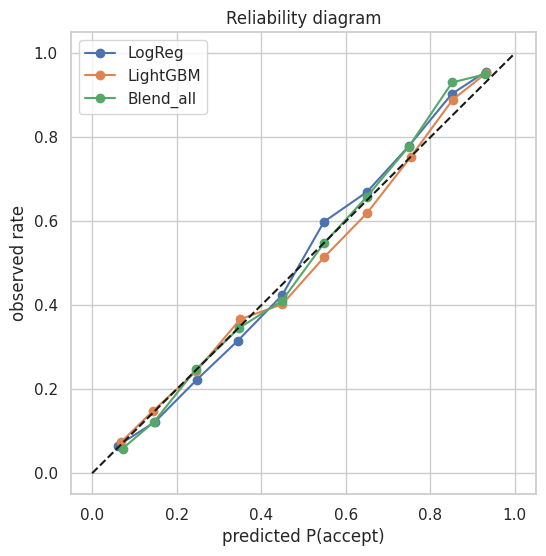

In [14]:
from sklearn.calibration import calibration_curve
plt.figure(figsize=(6,6))
for k in ['LogReg','LightGBM','Blend_all']:
    f,m = calibration_curve(y, oof[k], n_bins=10); plt.plot(m,f,marker='o',label=k)
plt.plot([0,1],[0,1],'k--'); plt.xlabel('predicted P(accept)'); plt.ylabel('observed rate'); plt.legend(); plt.title('Reliability diagram'); plt.show()

**Observation:** probabilities are close to the diagonal, so using them directly in the expected-cost rule is reasonable.

## 6. Cost evaluation of every model (brief's metric)
For each model: apply the person-specific decision rule to its out-of-fold probabilities, compute the **total town cost**, and measure fold-to-fold variation.

In [15]:
SCENARIO = 2
def evaluate(pr, scenario=SCENARIO, Hu=Hu, Hv=Hv):
    pred = decide(pr, Hu, Hv, scenario)
    tot = total_cost(y, pred, Hu, Hv, scenario)
    fc = [total_cost(y[b], pred[b], Hu[b], Hv[b], scenario) for a,b in folds]
    return pred, tot, np.std(fc)

base0 = total_cost(y, np.zeros(n,int), Hu, Hv, SCENARIO); oracle = total_cost(y, y, Hu, Hv, SCENARIO)
res=[]
for k in oof:
    pred,tot,sd = evaluate(oof[k])
    res.append(dict(model=k, total_cost=tot, cost_per_person=tot/n, saving_vs_all0=base0-tot,
                    pct_of_possible_saving=100*(base0-tot)/(base0-oracle), fold_sd=sd, share_sent=pred.mean()))
results = pd.DataFrame(res).set_index('model').sort_values('total_cost')
print(f'Baseline all-0: ${base0:,.0f} | oracle: ${oracle:,.0f}')
results.round(2)

Baseline all-0: $1,373,204 | oracle: $1,258,121


,total_cost,cost_per_person,saving_vs_all0,pct_of_possible_saving,fold_sd,share_sent
model,,,,,,
LightGBM,1345954.25,283.00,27249.50,23.68,3322.60,0.07
Blend_GBM,1346766.25,283.17,26437.50,22.97,3089.31,0.07
Blend_all,1347901.50,283.41,25302.25,21.99,3072.45,0.06
RandomForest,1348101.75,283.45,25102.00,21.81,2642.68,0.06
HistGB,1348109.50,283.45,25094.25,21.81,3122.78,0.08
LogReg,1350182.25,283.89,23021.50,20.00,3546.99,0.06


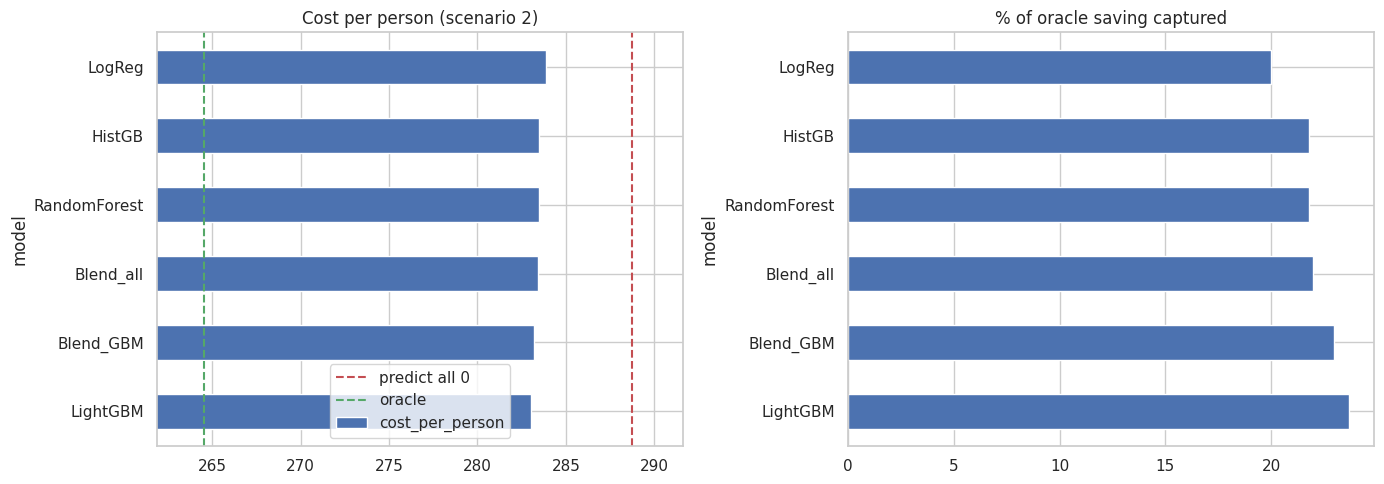

In [16]:
fig, ax = plt.subplots(1,2, figsize=(14,5))
results['cost_per_person'].plot.barh(ax=ax[0]); ax[0].axvline(base0/n, c='r', ls='--', label='predict all 0'); ax[0].axvline(oracle/n, c='g', ls='--', label='oracle'); ax[0].legend()
ax[0].set_xlim(min(oracle/n, results.cost_per_person.min())*0.99, base0/n*1.01); ax[0].set_title('Cost per person (scenario 2)')
results['pct_of_possible_saving'].plot.barh(ax=ax[1]); ax[1].set_title('% of oracle saving captured'); plt.tight_layout(); plt.show()

**How to read it:** `pct_of_possible_saving` shows how much of the gap between "send nobody" and perfect knowledge each model closes. Small values are expected: with realistic hospitalisation risk most people are cheaper to leave unvaccinated, so the model only needs to find the few high-risk, likely-to-accept people.

## 7. Sensitivity to the hospitalisation assumptions
The hospitalisation probability comes from AI estimates, so test whether our conclusion is robust to it (base risk across its AI-derived range 0.06–0.4 %, plus an extreme 1 % case, and vaccine effectiveness 40–80 %). The best model's saving vs the baselines is recomputed each time.

In [17]:
best_name = results.index[0]
srows=[]
for base in [BASE_RANGE[0], BASE_RISK, BASE_RANGE[1], 0.01]:
    for ve in [VAX_RANGE[0], VAX_EFFECT, VAX_RANGE[1]]:
        pu,pv = hosp_probs(train, base, ve); hu,hv = HOSP_COST*pu, HOSP_COST*pv
        pred = decide(oof[best_name], hu, hv, 2)
        c = total_cost(y,pred,hu,hv,2); c0 = total_cost(y,np.zeros(n,int),hu,hv,2); c1 = total_cost(y,np.ones(n,int),hu,hv,2); co = total_cost(y,y,hu,hv,2)
        srows.append(dict(base_risk=base, vaccine_eff=ve, model_pp=c/n, all0_pp=c0/n, all1_pp=c1/n, oracle_pp=co/n,
                          pct_saving_captured=100*(c0-c)/(c0-co) if c0>co else np.nan, share_sent=pred.mean()))
pd.DataFrame(srows).round(2)

,base_risk,vaccine_eff,model_pp,all0_pp,all1_pp,oracle_pp,pct_saving_captured,share_sent
0,0.00,0.4,233.27,233.70,530.23,227.25,6.66,0.02
1,0.00,0.6,232.98,233.70,527.01,224.02,7.40,0.03
2,0.00,0.8,232.00,233.70,523.78,220.80,13.19,0.04
3,0.00,0.4,285.77,288.73,575.58,272.60,18.33,0.05
4,0.00,0.6,283.00,288.73,567.52,264.53,23.68,0.07
5,0.00,0.8,280.07,288.73,559.45,256.47,26.84,0.10
6,0.00,0.4,427.64,441.59,701.56,398.57,32.44,0.12
7,0.00,0.6,417.39,441.59,680.05,377.07,37.50,0.16
8,0.00,0.8,406.12,441.59,658.54,355.56,41.22,0.19
9,0.01,0.4,759.39,808.46,1003.90,700.91,45.63,0.22


**Takeaway:** with the best-estimate base risk (0.15 %) a vaccine saves on average far less than its $500 cost, so only very high-risk people with a high acceptance probability are targeted and the policy is close to 'send nobody'. As base risk rises towards the top of the range, many more people qualify and the model's value increases. The model ranking is stable; the *share sent a vaccine* is what changes. Report this table to show the result is robust to the AI-sourced inputs.

## 8. Final ranking & submission files
Ranked by total town cost (scenario above) with a stability filter (drop models whose fold cost sd is > 5× the median). Each file contains the 0/1 decision **"send vaccine / predicted to accept"** for every test respondent.

In [18]:
final = results.copy()
bad = final.fold_sd > 5*final.fold_sd.median()
final = pd.concat([final[~bad], final[bad]]).head(5)
display(final[['total_cost','cost_per_person','pct_of_possible_saving','fold_sd','share_sent']].round(2))

p_unv_te, p_vac_te = hosp_probs(test)
for i,k in enumerate(final.index,1):
    pred_te = decide(test_proba[k], HOSP_COST*p_unv_te, HOSP_COST*p_vac_te, SCENARIO)
    pd.DataFrame({'respondent_id': ids, 'h1n1_vaccine': pred_te}).to_csv(f'submission_{i}_{k}.csv', index=False)
    print(f'#{i} {k:10s} predicted-accept share on test = {pred_te.mean():.2%}')

,total_cost,cost_per_person,pct_of_possible_saving,fold_sd,share_sent
model,,,,,
LightGBM,1345954.25,283.00,23.68,3322.60,0.07
Blend_GBM,1346766.25,283.17,22.97,3089.31,0.07
Blend_all,1347901.50,283.41,21.99,3072.45,0.06
RandomForest,1348101.75,283.45,21.81,2642.68,0.06
HistGB,1348109.50,283.45,21.81,3122.78,0.08


#1 LightGBM   predicted-accept share on test = 7.52%
#2 Blend_GBM  predicted-accept share on test = 6.99%
#3 Blend_all  predicted-accept share on test = 6.49%
#4 RandomForest predicted-accept share on test = 6.25%
#5 HistGB     predicted-accept share on test = 7.79%


In [19]:
try:
    from google.colab import files
    import glob
    for f in sorted(glob.glob('submission_*.csv')): files.download(f)
except ImportError:
    pass

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## 9. Conclusions & critical evaluation
* **Metric:** the sheet's cost = $500 per vaccine supplied or reimbursed + $25,000 × expected hospitalisations. Hospitalisation risk depends on the person and on whether they are *actually* vaccinated.
* **Key insight:** under the literal rules only *wasted* vaccines (false positives) are avoidable errors; if reimbursed people are treated as protected, the optimal policy is trivial (send nobody). The interesting – and more realistic – case is scenario 2, where the decision becomes person-specific: vaccinate when `P(accept) × ΔHospitalisationCost > $500 × P(refuse)`.
* **Models:** all reach CV AUC ≈ 0.85 and are reasonably calibrated; differences in cost between them are small relative to fold noise, so prefer the simple/stable ones (LightGBM, LogReg).
* **Inputs from generative AI:** the hospitalisation parameters come from an AI literature synthesis (CDC burden data, Van Kerkhove 2011, Lansbury 2017 etc.); age multipliers and `chronic_k` are judgements. Cross-check against other AIs/people and document; Section 7 shows how sensitive results are.
* **Limitations:** hospitalisation risk uses only age and chronic conditions (the dataset has few clinical features); we assume 100 % infection and that acceptance = the observed `h1n1_vaccine` label; no calibration beyond what the models give.
* **Extensions:** isotonic calibration, extra features in the risk model (health worker, pregnancy proxy), using an external hospitalisation dataset as the sheet suggests.